# Tugas 2 - Milestone 1 Final Project
## Market Prioritization UMKM: Wilayah Target Sourcing Leads B2B SaaS

**Studi kasus:** Skalar Solutions - Klay (POS + AI Sales Analytics)
**Kelompok:** 13
**Anggota:**
1. Ayu Safitri (2610501106) - Data collection & data understanding
2. Carissa Zia W. F (2610514008) - Data preparation & merging
3. Gerard Harjuno N (2610512189) - EDA, visualisasi & rancangan bobot ICP

> Notebook ini hanya sampai perancangan bobot ICP; K-Means, skor akhir, Top 5, dan uji sensitivitas dikerjakan pada milestone berikutnya.

## Ringkasan Eksekutif

Klay menjual POS + AI Sales Analytics ke UMKM. Untuk memprioritaskan wilayah sourcing leads, kami menyusun kerangka **Ideal Customer Profile (ICP)** di **35 kabupaten/kota Jawa Tengah** dengan empat sumber publik BPS/Dinkop Jateng (2023-2024).

Temuan utama:

- Setelah pembersihan dan filter kualitas data, **30 wilayah** lolos dan siap dianalisis.
- **Kabupaten Banyumas, Cilacap, Kebumen, Purbalingga, dan Pemalang** memimpin jumlah unit IMK, tetapi kepadatan IMK tidak otomatis sejalan dengan PDRB per kapita (korelasi -0,30).
- **Kota Surakarta dan Kota Semarang** unggul pada kepadatan pedagang pasar, IPM, PDRB, dan simpanan per kapita. Keduanya adalah segmen "siap digital" dengan daya beli tinggi.
- Sebaliknya, kabupaten dengan IMK padat tetapi PDRB/IPM rendah (mis. Kebumen, Wonosobo, Banjarnegara) adalah pasar volume besar dengan **gap digitalisasi** yang justru menjadi peluang Klay.
- Rancangan bobot ICP: Ukuran Pasar 25%, Kepadatan Sektor Target 25%, Kesiapan Digital 20%, Adopsi Pembayaran Digital 15%, Aktivitas Ekonomi 15%.

## Bagian 1 - Data Collection & Data Understanding

### 1.1 Tabel sumber data

| No | Sumber | Link akses | Alasan dipilih | Level agregasi | Kolom kunci | Keterbatasan |
|---|---|---|---|---|---|---|
| 1 | BPS Jawa Tengah, *Provinsi Jawa Tengah Dalam Angka 2025* | [Publikasi BPS](https://jateng.bps.go.id/id/publication/2025/02/28/6f9ad30e8755ed2b706cb979/provinsi-jawa-tengah-dalam-angka-2025.html) | Satu publikasi resmi memuat IMK, PDRB per kapita, sarana perdagangan, simpanan, dan tabungan per kabupaten/kota | Kabupaten/kota (35) | Tabel 7.2.2 (IMK 2023), 13.2.5 (PDRB 2024), 10.2.23 (sarana 2024), 10.3.2/10.3.3 (simpanan/tabungan 2024) | Sebagian tabel berupa PDF; nama wilayah tidak membedakan Kabupaten/Kota; ada watermark dan sel "en dash" |
| 2 | BPS Jawa Tengah, *Penduduk, Laju Pertumbuhan, Kepadatan, dan Rasio Jenis Kelamin menurut Kabupaten/Kota 2024* | [Dataset CKAN](https://data.jatengprov.go.id/dataset/79a-penduduk-laju-pertumbuhan-penduduk-distribusi-persentase-penduduk-kepadatan-penduduk-rasio-jenis) | Denominator kepadatan sektor dan konteks demografi | Kabupaten/kota (35) | `kod_wil`, `kab_ko`, `jumlah_penduduk`, `kepadatan_penduduk` | Hanya satu tahun; proyeksi penduduk, bukan sensus |
| 3 | BPS Jawa Tengah, *Indeks Pembangunan Manusia (IPM) menurut Kabupaten/Kota 2024* | [Dataset CKAN](https://data.jatengprov.go.id/dataset/6c4-indeks-pembangunan-manusia-ipm-menurut-kabupaten-kota) | Proxy kesiapan digital dan kualitas sumber daya manusia | Kabupaten/kota (35) | `kod_wil`, `indikator`, `indeks` | IPM bersifat agregat; tidak mengukur literasi digital secara langsung |
| 4 | Dinkop Jateng, *Jumlah UMKM Binaan Jawa Tengah* | [Dataset CKAN](https://data.jatengprov.go.id/dataset/7e5-jumlah-umkm-binaan-jawa-tengah) | Konteks pertumbuhan populasi UMKM di level provinsi | Provinsi (time series 2019-2024) | `tahun`, jumlah UMKM binaan | Hanya UMKM **binaan**, bukan total UMKM; 2024 baru s.d. TW II |

### 1.2 Alasan pemilihan studi kasus

Jawa Tengah dipilih karena portal CKAN-nya menyediakan data per kabupaten/kota yang relatif lengkap dan dapat diunduh tanpa login. Jumlah 35 wilayah melewati syarat minimal 20 wilayah, dan heterogenitas kabupaten-kota memberi variasi yang cukup untuk analisis segmentasi.

### 1.3 Definisi operasional

- **IMK**: Industri Mikro dan Kecil, unit usaha manufaktur berskala mikro/kecil. Ini **proxy** kepadatan sektor target, bukan total UMKM.
- **Pedagang pasar**: Pedagang yang berjualan di pasar rakyat. Ini **proxy** kepadatan retail/F&B tradisional.
- **Sarana perdagangan**: Pasar, supermarket, dan pedagang pasar. Bukan seluruh kanal retail modern.
- **UMKM binaan**: UMKM yang difasilitasi Dinkop Jateng. Bukan populasi seluruh UMKM, sehingga tidak boleh dijumlahkan dengan IMK.

### 1.4 Data dictionary

| Kelompok | Kolom | Satuan | Sumber |
|---|---|---|---|
| Identitas | `kode_wilayah`, `wilayah`, `tipe` | - | BPS (kode dan nama kanonik) |
| Demografi | `penduduk_ribu`, `kepadatan_per_km2` | ribu jiwa; jiwa/km2 | BPS Penduduk 2024 |
| IPM | `ipm`, `pengeluaran_per_kapita`, `harapan_lama_sekolah`, `rata_rata_lama_sekolah`, `usia_harapan_hidup` | indeks; ribu Rp/orang/tahun; tahun | BPS IPM 2024 |
| Sektor | `imk_unit`, `imk_tenaga_kerja`, `imk_nilai_produksi` | unit; orang; ribu Rp | BPS JTG 2025 tabel 7.2.2 |
| Retail | `supermarket`, `pasar`, `pedagang_pasar` | unit; unit; orang | BPS JTG 2025 tabel 10.2.23 |
| Ekonomi | `pdrb_per_kapita_2024`, `simpanan_2024`, `tabungan_2024` | ribu Rp; juta Rp; juta Rp | BPS JTG 2025 tabel 13.2.5, 10.3.2, 10.3.3 |
| Turunan | `imk_per_100k`, `pedagang_per_100k`, `pasar_per_100k`, `simpanan_per_kapita_juta`, `tabungan_per_kapita_juta`, `sektor_target_per_100k` | per 100.000 penduduk; juta Rp/kapita | Kalkulasi penulis |
| Konteks provinsi | `prov_umkm_growth_2023`, `prov_umkm_binaan_2023` | persen; unit | Dinkop Jateng |

## Bagian 2 - Data Preparation

### 2.1 Pembersihan data

Langkah yang dilakukan:

1. **Ekstraksi PDF**: tabel diekstrak dengan `pdfplumber`, lalu angka dibersihkan dari watermark dan pemisah ribuan.
2. **Nama wilayah**: PDF tidak membedakan "Semarang" kabupaten vs kota. Nama kanonik diambil dari file penduduk berdasarkan urutan 35 wilayah dan `kode_wilayah` (3301-3329 kabupaten, 3371-3376 kota).
3. **Sel kosong**: pada tabel sarana perdagangan, tanda "en dash" berarti nol outlet, bukan missing. Nilai tersebut diisi 0.
4. **Duplikat dan missing**: diperiksa pada level `kode_wilayah` dan `wilayah`.
5. **Tipe data**: seluruh kolom numerik dipastikan bertipe angka; tidak ada nilai negatif yang tidak wajar.

Validasi yang dijalankan:

In [20]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter
from sklearn.preprocessing import MinMaxScaler

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.titlesize"] = 12
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)

In [21]:
master = pd.read_csv("data/processed/master_raw.csv")
umkm = pd.read_csv("data/processed/provinsi_umkm_series.csv")

print(f"master_raw : {master.shape[0]} baris x {master.shape[1]} kolom")
print(f"UMKM series: {umkm.shape[0]} tahun ({umkm.tahun.min()}-{umkm.tahun.max()})")
master.head()

master_raw : 35 baris x 27 kolom
UMKM series: 6 tahun (2019-2024)


,kode_wilayah,wilayah,penduduk_ribu,kepadatan_per_km2,tipe,ipm,pengeluaran_per_kapita,harapan_lama_sekolah,rata_rata_lama_sekolah,usia_harapan_hidup,imk_unit,imk_tenaga_kerja,imk_nilai_produksi,pdrb_per_kapita_2024,supermarket,pasar,pedagang_pasar,simpanan_2024,tabungan_2024,prov_umkm_growth_2023,prov_umkm_binaan_2023,imk_per_100k,pedagang_per_100k,pasar_per_100k,simpanan_per_kapita_juta,tabungan_per_kapita_juta,sektor_target_per_100k
0,3301,Cilacap,2027.4,901,Kabupaten,72.38,11868.0,12.69,7.40,74.57,52570.0,92590.0,2.792646e+09,67077.0,4.0,33.0,5282.0,2899639.0,10290137.0,3.015301,186024,2592.976226,260.530729,1.627701,1.430225,5.075534,2853.506955
1,3302,Banyumas,1847.1,1391,Kabupaten,74.52,12960.0,13.34,7.91,74.34,54328.0,122895.0,6.977360e+09,40151.0,5.0,28.0,8954.0,4513589.0,10410148.0,3.015301,186024,2941.259271,484.759894,1.515890,2.443608,5.635942,3426.019165
2,3303,Purbalingga,1037.6,1334,Kabupaten,70.69,11343.0,12.03,7.36,73.56,47284.0,72933.0,1.591214e+09,32147.0,2.0,20.0,4159.0,1451640.0,3857083.0,3.015301,186024,4557.054742,400.828836,1.927525,1.399036,3.717312,4957.883577
3,3304,Banjarnegara,1057.6,993,Kabupaten,69.60,10595.0,11.83,6.87,74.66,20701.0,27200.0,4.865229e+08,27640.0,4.0,23.0,11821.0,1079162.0,3801613.0,3.015301,186024,1957.356278,1117.719365,2.174735,1.020388,3.594566,3075.075643
4,3305,Kebumen,1414.8,1060,Kabupaten,71.93,10176.0,13.39,7.87,73.96,48975.0,93529.0,3.878663e+09,27288.0,16.0,41.0,19719.0,1270129.0,5960515.0,3.015301,186024,3461.620017,1393.765903,2.897936,0.897745,4.212974,4855.385920


In [22]:
ringkas = pd.DataFrame({
    "kolom": master.columns,
    "tipe": master.dtypes.astype(str).values,
    "missing": master.isna().sum().values,
    "contoh": [master[c].dropna().iloc[0] for c in master.columns],
})
ringkas

,kolom,tipe,missing,contoh
0,kode_wilayah,int64,0,3301
1,wilayah,str,0,Cilacap
2,penduduk_ribu,float64,0,2027.4
3,kepadatan_per_km2,int64,0,901
4,tipe,str,0,Kabupaten
5,ipm,float64,0,72.38
6,pengeluaran_per_kapita,float64,0,11868.0
7,harapan_lama_sekolah,float64,0,12.69
8,rata_rata_lama_sekolah,float64,0,7.4
9,usia_harapan_hidup,float64,0,74.57


In [23]:
print("Duplikat kode wilayah :", master.kode_wilayah.duplicated().sum())
print("Duplikat nama wilayah :", master.wilayah.duplicated().sum())
print("Jumlah wilayah unik   :", master.wilayah.nunique())
print("Total missing         :", int(master.isna().sum().sum()))
print("Rentang kode          :", master.kode_wilayah.min(), "-", master.kode_wilayah.max())

assert master.shape[0] == 35
assert master.wilayah.nunique() == 35
assert master.isna().sum().sum() == 0
print("Validasi struktur: LULUS")

Duplikat kode wilayah : 0
Duplikat nama wilayah : 0
Jumlah wilayah unik   : 35
Total missing         : 0
Rentang kode          : 3301 - 3376
Validasi struktur: LULUS


### 2.2 Merging lintas level

Data kabupaten/kota digabung dengan `kode_wilayah` dan `wilayah` sebagai kunci. Data provinsi (time series UMKM binaan) **tidak di-join secara aditif**, karena level agregasinya berbeda. Yang dilakukan adalah **broadcast satu kolom konteks** (`prov_umkm_growth_2023`) ke seluruh kabupaten/kota, lalu nilainya dipakai sebagai fitur konteks pada analisis, bukan sebagai tambahan kuantitas.

Mengapa tidak dijumlahkan: total UMKM binaan provinsi 2023 = **186.024**, sedangkan total unit IMK 35 kabupaten/kota = **862.926**. Keduanya mengukur populasi yang berbeda (UMKM binaan vs seluruh unit industri mikro/kecil), sehingga penjumlahan akan menyesatkan. Perbedaan definisi ini dicatat sebagai limitasi.

Validasi merge:

In [24]:
prov_growth = umkm.loc[umkm.tahun == 2023, "pertumbuhan_yoy_persen"].iloc[0]
print(f"Pertumbuhan UMKM binaan provinsi 2023: {prov_growth:.2f}%")
print("Kolom konteks terisi di semua baris :", master.prov_umkm_growth_2023.notna().all())
print("Nilai unik kolom konteks           :", master.prov_umkm_growth_2023.nunique())
print("Total unit IMK 35 wilayah          :", f"{master.imk_unit.sum():,.0f}")
print("Total UMKM binaan provinsi 2023    :", f"{master.prov_umkm_binaan_2023.iloc[0]:,.0f}")

Pertumbuhan UMKM binaan provinsi 2023: 3.02%
Kolom konteks terisi di semua baris : True
Nilai unik kolom konteks           : 1
Total unit IMK 35 wilayah          : 862,926
Total UMKM binaan provinsi 2023    : 186,024


### 2.3 Kriteria penggugur dan wilayah tereliminasi

Filter dipakai untuk membuang wilayah yang terlalu kecil atau ekstrem, agar segmentasi tidak didominasi outlier. Kriteria:

1. **Data kunci kosong** - tidak ada wilayah yang gugur karena seluruh data kunci terisi.
2. **Skala terlalu kecil**: `imk_unit < 10.000` unit. Wilayah dengan basis industri sangat kecil sulit memberi volume leads yang layak untuk B2B SaaS.
3. **Outlier kepadatan**: `imk_per_100k > Q3 + 1.5 x IQR`. Nilai ekstrem dapat mendistorsi normalisasi dan bobot.

Ambang 10.000 dipilih agar kota-kota kecil dengan basis manufaktur tipis keluar, tetapi wilayah dengan basis memadai tetap lolos. Hasilnya **30 wilayah** (di atas syarat minimal 20).

In [25]:
q1 = master.imk_per_100k.quantile(0.25)
q3 = master.imk_per_100k.quantile(0.75)
iqr = q3 - q1
upper = q3 + 1.5 * iqr

master["gugur_imk_kecil"] = master.imk_unit < 10_000
master["gugur_outlier_density"] = master.imk_per_100k > upper
master["alasan_gugur"] = ""

master.loc[master.gugur_imk_kecil, "alasan_gugur"] = "IMK < 10.000 unit"
master.loc[master.gugur_outlier_density, "alasan_gugur"] = (
    master.loc[master.gugur_outlier_density, "alasan_gugur"]
    .apply(lambda x: (x + "; " if x else "") + f"IMK/100k > {upper:,.0f} (outlier)")
)

eliminated = master[master.alasan_gugur != ""].copy()
clean = master[master.alasan_gugur == ""].copy().reset_index(drop=True)

print(f"Batas outlier IMK/100k : {upper:,.0f}")
print(f"Wilayah gugur          : {len(eliminated)}")
print(f"Wilayah lolos          : {len(clean)}")
eliminated[["wilayah", "tipe", "imk_unit", "imk_per_100k", "alasan_gugur"]]

Batas outlier IMK/100k : 5,298
Wilayah gugur          : 5
Wilayah lolos          : 30


,wilayah,tipe,imk_unit,imk_per_100k,alasan_gugur
25,Pekalongan,Kabupaten,60456.0,5932.875368,"IMK/100k > 5,298 (outlier)"
29,Kota Magelang,Kota,3025.0,2471.405229,IMK < 10.000 unit
31,Kota Salatiga,Kota,6301.0,3130.153999,IMK < 10.000 unit
33,Kota Pekalongan,Kota,9988.0,3110.557459,IMK < 10.000 unit
34,Kota Tegal,Kota,2947.0,1031.140658,IMK < 10.000 unit


**Catatan penting:** filter ini secara tidak proporsional mengeluarkan kota-kota kecil (Kota Magelang, Salatiga, Pekalongan, Tegal). Dari 6 kota, hanya Kota Semarang dan Kota Surakarta yang lolos. Ini adalah **trade-off** yang disadari: fokus pada wilayah dengan basis sektor cukup besar, tetapi analisis kota-kota kecil perlu dilakukan terpisah pada milestone berikutnya.

**Pemetaan sektor:** Brief ICP Klay menyasar ritel, F&B, dan jasa transaksi kecil berulang. Data publik yang dipakai tidak menyediakan komposisi sektor per kabupaten/kota. Karena itu, jumlah unit IMK dipakai sebagai proxy umum usaha mikro/kecil dan pedagang pasar sebagai proxy ritel/F&B tradisional. Komposisi F&B dan jasa per wilayah tidak dapat difilter terpisah, dan filter sektor tanpa transaksi harian rutin tidak dapat diterapkan pada level ini; filter hanya dilakukan pada level wilayah. Keterbatasan ini dicatat eksplisit, bukan diisi dengan tebakan.

### 2.4 Normalisasi Min-Max

Normalisasi dilakukan pada 30 wilayah yang lolos, dengan rumus:

$$x'_{i} = \frac{x_i - \min(x)}{\max(x) - \min(x)}$$

Fitur yang dinormalisasi mewakili lima komponen ICP. Hasil normalisasi berada pada rentang 0-1 dan disimpan sebagai kolom `*_norm`/komponen.

In [26]:
features = {
    "imk_unit": "ukuran_pasar_imk",
    "pedagang_pasar": "ukuran_pasar_pedagang",
    "imk_per_100k": "kepadatan_imk",
    "pedagang_per_100k": "kepadatan_pedagang",
    "ipm": "kesiapan_ipm",
    "pengeluaran_per_kapita": "kesiapan_pengeluaran",
    "simpanan_per_kapita_juta": "adopsi_simpanan",
    "tabungan_per_kapita_juta": "adopsi_tabungan",
    "pdrb_per_kapita_2024": "aktivitas_pdrb",
}

scaler = MinMaxScaler()
norm = pd.DataFrame(
    scaler.fit_transform(clean[list(features)]),
    columns=[features[c] for c in features],
    index=clean.index,
)
clean = pd.concat([clean, norm], axis=1)

print("Rentang setelah normalisasi:")
print(norm.agg(["min", "max"]).T.to_string())
norm.describe().round(3)

Rentang setelah normalisasi:
                       min  max
ukuran_pasar_imk       0.0  1.0
ukuran_pasar_pedagang  0.0  1.0
kepadatan_imk          0.0  1.0
kepadatan_pedagang     0.0  1.0
kesiapan_ipm           0.0  1.0
kesiapan_pengeluaran   0.0  1.0
adopsi_simpanan        0.0  1.0
adopsi_tabungan        0.0  1.0
aktivitas_pdrb         0.0  1.0


,ukuran_pasar_imk,ukuran_pasar_pedagang,kepadatan_imk,kepadatan_pedagang,kesiapan_ipm,kesiapan_pengeluaran,adopsi_simpanan,adopsi_tabungan,aktivitas_pdrb
count,30.000,30.000,30.000,30.000,30.000,30.000,30.000,30.000,30.000
mean,0.348,0.380,0.375,0.245,0.334,0.308,0.101,0.126,0.195
std,0.294,0.227,0.264,0.181,0.242,0.236,0.232,0.205,0.251
min,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
25%,0.117,0.215,0.188,0.117,0.182,0.132,0.016,0.040,0.057
50%,0.288,0.348,0.335,0.234,0.290,0.253,0.028,0.069,0.108
75%,0.526,0.483,0.550,0.307,0.427,0.415,0.051,0.102,0.226
max,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000


Komponen ICP dibentuk dari rata-rata sederhana indikator terormalisasi. **Ini bukan skor akhir**; komponen hanya dipakai untuk EDA dan verifikasi arah indikator. Pembobotan dan skor akhir sengaja belum dihitung karena berada di luar cakupan Tugas 2.

In [27]:
clean["komp_ukuran_pasar"] = clean[["ukuran_pasar_imk", "ukuran_pasar_pedagang"]].mean(axis=1)
clean["komp_kepadatan_sektor"] = clean[["kepadatan_imk", "kepadatan_pedagang"]].mean(axis=1)
clean["komp_kesiapan_digital"] = clean[["kesiapan_ipm", "kesiapan_pengeluaran"]].mean(axis=1)
clean["komp_adopsi_digital"] = clean[["adopsi_simpanan", "adopsi_tabungan"]].mean(axis=1)
clean["komp_aktivitas_ekonomi"] = clean["aktivitas_pdrb"]

komp_cols = [
    "komp_ukuran_pasar",
    "komp_kepadatan_sektor",
    "komp_kesiapan_digital",
    "komp_adopsi_digital",
    "komp_aktivitas_ekonomi",
]
clean[komp_cols].describe().round(3)

,komp_ukuran_pasar,komp_kepadatan_sektor,komp_kesiapan_digital,komp_adopsi_digital,komp_aktivitas_ekonomi
count,30.000,30.000,30.000,30.000,30.000
mean,0.364,0.310,0.321,0.113,0.195
std,0.178,0.164,0.231,0.215,0.251
min,0.083,0.026,0.003,0.000,0.000
25%,0.235,0.201,0.155,0.029,0.057
50%,0.364,0.303,0.273,0.046,0.108
75%,0.436,0.400,0.452,0.077,0.226
max,0.938,0.662,1.000,0.911,1.000


## Bagian 3 - Exploratory Data Analysis

EDA dilakukan pada 30 wilayah yang lolos. Fokusnya bukan mencari korelasi kausal, melainkan memetakan variasi antarwilayah dan mencari kombinasi indikator yang relevan untuk ICP Klay.

### 3.1 Univariat - sebaran jumlah unit IMK

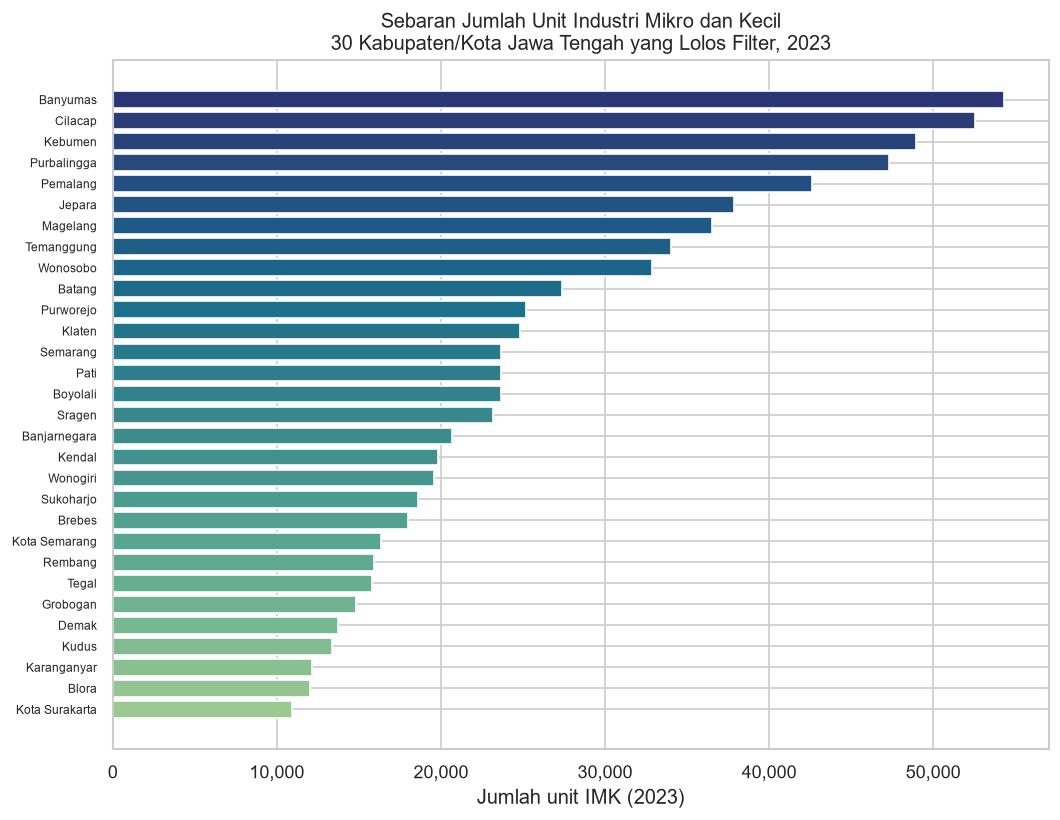

In [28]:
fig, ax = plt.subplots(figsize=(9, 7))
plot_df = clean.sort_values("imk_unit")
colors = sns.color_palette("crest", n_colors=len(plot_df))
ax.barh(plot_df.wilayah, plot_df.imk_unit, color=colors)
ax.set_xlabel("Jumlah unit IMK (2023)")
ax.set_ylabel("")
ax.set_title("Sebaran Jumlah Unit Industri Mikro dan Kecil\n30 Kabupaten/Kota Jawa Tengah yang Lolos Filter, 2023")
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:,.0f}"))
ax.tick_params(axis="y", labelsize=7)
plt.tight_layout()
plt.savefig("figures/fig1_imk_distribution.png", bbox_inches="tight")
plt.show()

**Interpretasi bisnis:** distribusi jumlah IMK sangat timpang. Banyumas, Cilacap, Kebumen, Purbalingga, dan Pemalang masing-masing memiliki >42 ribu unit, sedangkan wilayah lain jauh lebih kecil. Untuk Klay, lima wilayah ini adalah **pasar volume** untuk paket dasar POS, tetapi belum tentu yang paling siap digital. Prioritas sebaiknya mempertimbangkan kepadatan relatif dan kesiapan digital, bukan hanya jumlah absolut.

### 3.2 Univariat - kepadatan IMK menurut tipe wilayah

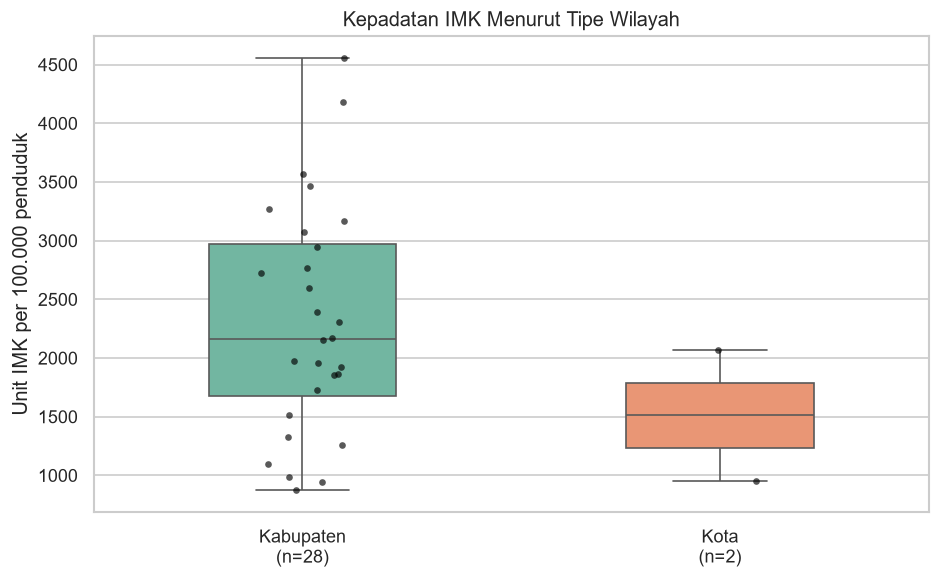

           imk_unit  imk_per_100k  pedagang_per_100k  pdrb_per_kapita_2024   ipm
tipe                                                                            
Kabupaten   26892.3        2306.9              856.5               42305.4  73.3
Kota        13612.0        1510.3             2030.8              139550.0  84.8


In [29]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=clean, x="tipe", y="imk_per_100k", hue="tipe", legend=False,
            palette="Set2", width=0.45, ax=ax)
sns.stripplot(data=clean, x="tipe", y="imk_per_100k", color="black",
              alpha=0.65, size=4, ax=ax)
counts = clean.tipe.value_counts()
ax.set_xticklabels([f"{t}\n(n={counts[t]})" for t in ["Kabupaten", "Kota"]])
ax.set_xlabel("")
ax.set_ylabel("Unit IMK per 100.000 penduduk")
ax.set_title("Kepadatan IMK Menurut Tipe Wilayah")
plt.tight_layout()
plt.savefig("figures/fig2_boxplot_imk_density.png", bbox_inches="tight")
plt.show()

print(clean.groupby("tipe")[["imk_unit", "imk_per_100k", "pedagang_per_100k", "pdrb_per_kapita_2024", "ipm"]]
      .mean().round(1).to_string())

**Interpretasi bisnis:** kabupaten memiliki rata-rata unit IMK jauh lebih besar (26.892 vs 13.612), tetapi kepadatan per 100 ribu penduduk juga lebih tinggi (2.307 vs 1.510). Kota yang lolos justru unggul pada kepadatan pedagang pasar, PDRB, dan IPM. Artinya, **profil risiko dan pendekatan akuisisi berbeda**: kabupaten cocok untuk penetrasi volume manufaktur/retail tradisional, kota cocok untuk merchant yang sudah siap digital dan bertransaksi lebih tinggi.

### 3.3 Bivariat - PDRB per kapita vs kepadatan pedagang pasar

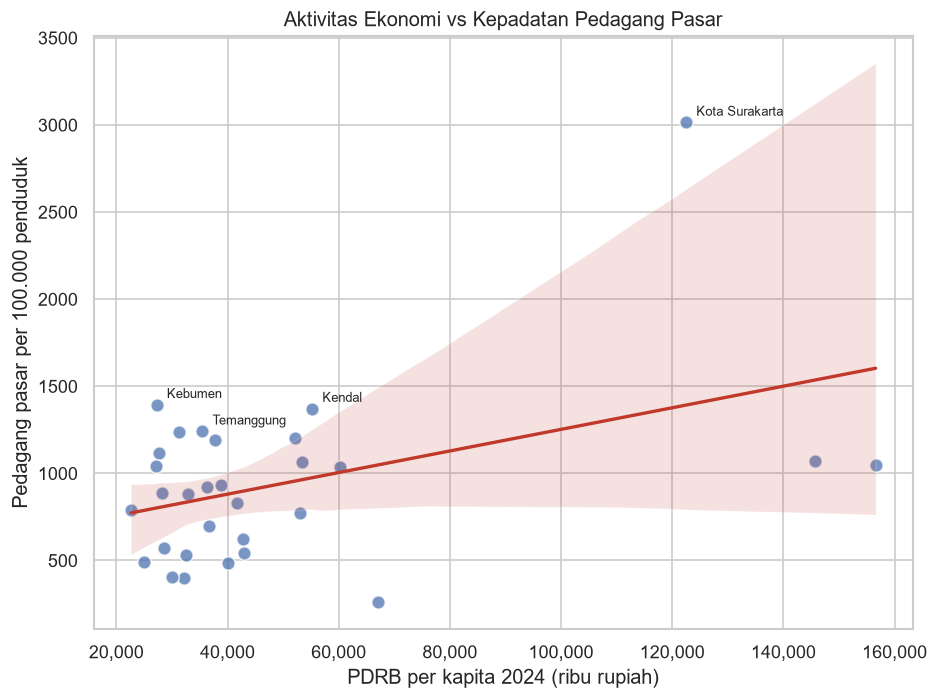

Korelasi PDRB vs pedagang/100k: 0.42


In [30]:
fig, ax = plt.subplots(figsize=(8, 6))
sns.regplot(data=clean, x="pdrb_per_kapita_2024", y="pedagang_per_100k", ax=ax,
            scatter_kws={"s": 65, "alpha": 0.75, "edgecolor": "white"},
            line_kws={"color": "#c0392b", "lw": 2})
for _, r in clean.nlargest(4, "pedagang_per_100k").iterrows():
    ax.annotate(r.wilayah, (r.pdrb_per_kapita_2024, r.pedagang_per_100k),
                textcoords="offset points", xytext=(6, 4), fontsize=8)
ax.set_xlabel("PDRB per kapita 2024 (ribu rupiah)")
ax.set_ylabel("Pedagang pasar per 100.000 penduduk")
ax.set_title("Aktivitas Ekonomi vs Kepadatan Pedagang Pasar")
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:,.0f}"))
plt.tight_layout()
plt.savefig("figures/fig3_pdrb_vs_pedagang.png", bbox_inches="tight")
plt.show()

print("Korelasi PDRB vs pedagang/100k:", round(clean.pdrb_per_kapita_2024.corr(clean.pedagang_per_100k), 2))

**Interpretasi bisnis:** korelasi positif sedang (r = 0,42). Wilayah dengan aktivitas ekonomi tinggi cenderung memiliki ekosistem pedagang pasar yang padat. Kota Surakarta adalah outlier positif: PDRB tinggi dan kepadatan pedagang sangat tinggi. Sebaliknya, beberapa kabupaten berpendapatan rendah tetap memiliki kepadatan pedagang tinggi (Kebumen, Temanggung, Purworejo), menandakan **aktivitas retail tradisional yang besar tetapi daya beli belum tinggi** - kandidat untuk paket hemat dan edukasi digital.

### 3.4 Bivariat - IPM vs kepadatan IMK

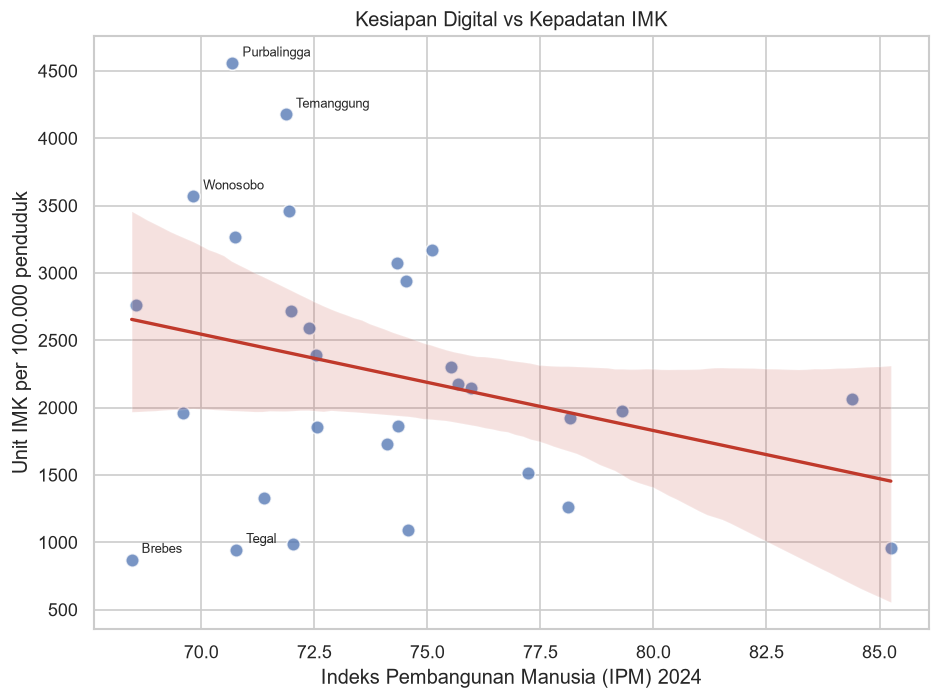

Korelasi IPM vs IMK/100k: -0.3


In [31]:
fig, ax = plt.subplots(figsize=(8, 6))
sns.regplot(data=clean, x="ipm", y="imk_per_100k", ax=ax,
            scatter_kws={"s": 65, "alpha": 0.75, "edgecolor": "white"},
            line_kws={"color": "#c0392b", "lw": 2})
label_df = pd.concat([clean.nlargest(3, "imk_per_100k"), clean.nsmallest(2, "imk_per_100k")])
for _, r in label_df.iterrows():
    ax.annotate(r.wilayah, (r.ipm, r.imk_per_100k),
                textcoords="offset points", xytext=(6, 4), fontsize=8)
ax.set_xlabel("Indeks Pembangunan Manusia (IPM) 2024")
ax.set_ylabel("Unit IMK per 100.000 penduduk")
ax.set_title("Kesiapan Digital vs Kepadatan IMK")
plt.tight_layout()
plt.savefig("figures/fig4_ipm_vs_imk.png", bbox_inches="tight")
plt.show()

print("Korelasi IPM vs IMK/100k:", round(clean.ipm.corr(clean.imk_per_100k), 2))

**Interpretasi bisnis:** korelasinya negatif lemah (r = -0,30). Kabupaten dengan IMK padat (Purbalingga, Temanggung, Kebumen, Batang) justru memiliki IPM menengah, bukan tertinggi. Ini adalah **gap yang menarik**: basis usaha besar, tetapi kesiapan digital belum matang. Klay dapat memposisikan diri sebagai alat bantu adopsi digital, bukan sekadar POS, di wilayah seperti ini. Sebaliknya, kota dengan IPM tinggi tetapi IMK rendah lebih cocok untuk produk analytics yang sudah advanced.

### 3.5 Multivariat - peta prioritas awal

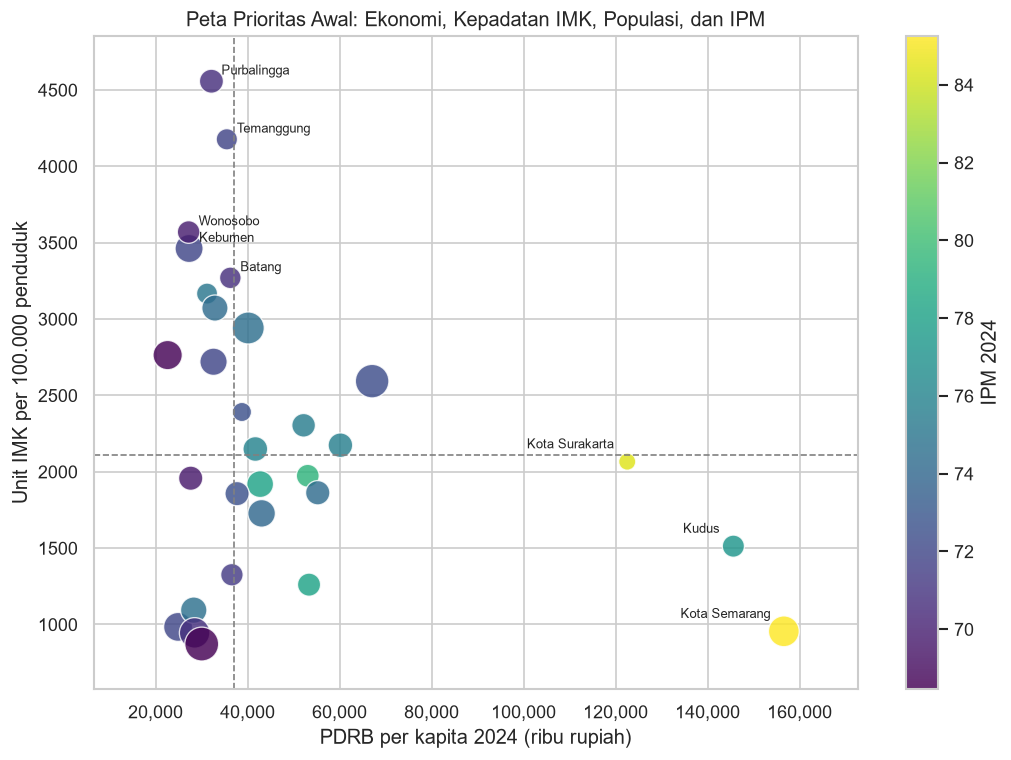

In [32]:
fig, ax = plt.subplots(figsize=(9, 6.5))
sc = ax.scatter(clean.pdrb_per_kapita_2024, clean.imk_per_100k,
                s=clean.penduduk_ribu / 5, c=clean.ipm, cmap="viridis",
                alpha=0.82, edgecolor="white", linewidth=0.8)
ax.axvline(clean.pdrb_per_kapita_2024.median(), color="grey", ls="--", lw=1)
ax.axhline(clean.imk_per_100k.median(), color="grey", ls="--", lw=1)

for _, r in clean.nlargest(5, "imk_per_100k").iterrows():
    ax.annotate(r.wilayah, (r.pdrb_per_kapita_2024, r.imk_per_100k),
                textcoords="offset points", xytext=(6, 4), fontsize=8)
for _, r in clean.nlargest(3, "pdrb_per_kapita_2024").iterrows():
    ax.annotate(r.wilayah, (r.pdrb_per_kapita_2024, r.imk_per_100k),
                textcoords="offset points", xytext=(-8, 8), ha="right", fontsize=8)
ax.margins(x=0.12, y=0.08)

cbar = plt.colorbar(sc, ax=ax)
cbar.set_label("IPM 2024")
ax.set_xlabel("PDRB per kapita 2024 (ribu rupiah)")
ax.set_ylabel("Unit IMK per 100.000 penduduk")
ax.set_title("Peta Prioritas Awal: Ekonomi, Kepadatan IMK, Populasi, dan IPM")
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:,.0f}"))
plt.tight_layout()
plt.savefig("figures/fig5_multivariate_bubble.png", bbox_inches="tight")
plt.show()

**Interpretasi bisnis:** empat kuadran memberi arah strategi:

- **Kanan atas** (PDRB tinggi, IMK padat): wilayah "siap scale" - prioritas untuk paket lengkap.
- **Kiri atas** (PDRB rendah, IMK padat): volume besar dengan daya beli terbatas - paket hemat, onboarding intensif.
- **Kanan bawah** (PDRB tinggi, IMK rendah): ekonomi jasa/perdagangan - prospek merchant retail, bukan manufaktur.
- **Kiri bawah** (keduanya rendah): prioritas rendah untuk sourcing awal.

Ukuran gelembung menunjukkan populasi; warna menunjukkan IPM. Kota Semarang dan Surakarta berada di kanan dengan IPM tinggi, sedangkan Kebumen, Wonosobo, dan Banjarnegara berada di kiri atas dengan populasi besar dan IPM menengah - kombinasi yang menarik untuk ekspansi berbasis volume.

### 3.6 Multivariat - heatmap komponen ICP

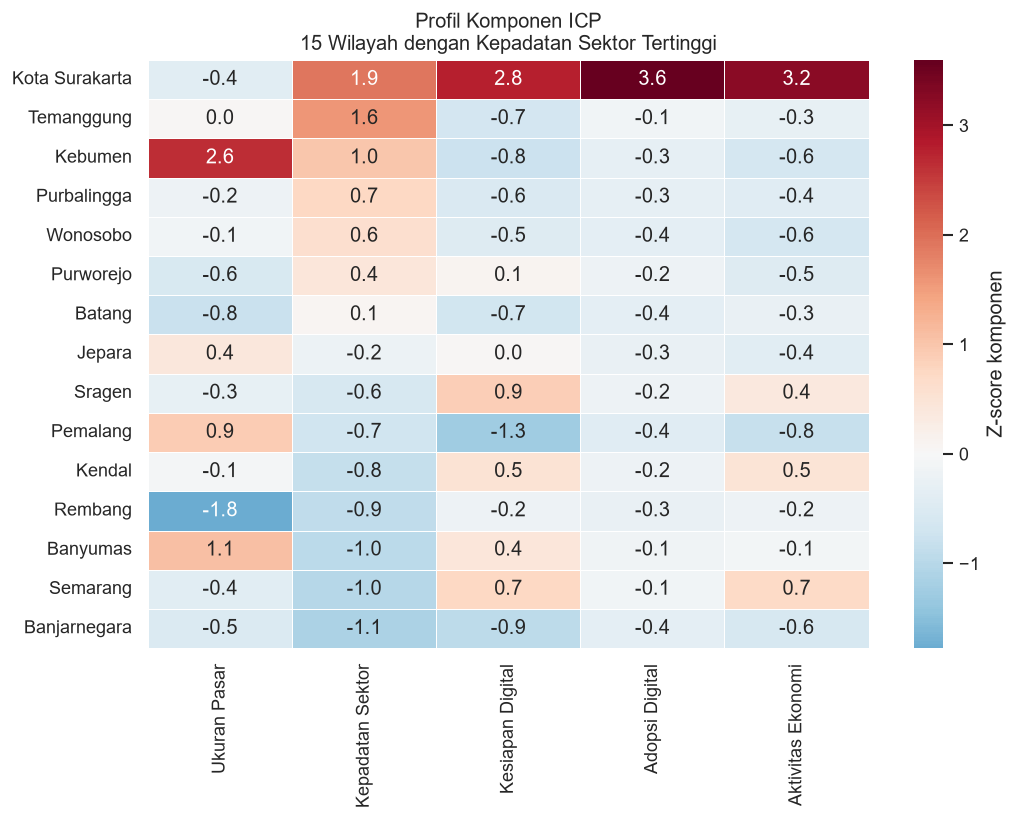

In [33]:
top15 = clean.sort_values("komp_kepadatan_sektor", ascending=False).head(15).set_index("wilayah")
z = (top15[komp_cols] - top15[komp_cols].mean()) / top15[komp_cols].std()
z.columns = ["Ukuran Pasar", "Kepadatan Sektor", "Kesiapan Digital", "Adopsi Digital", "Aktivitas Ekonomi"]

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(z, cmap="RdBu_r", center=0, annot=True, fmt=".1f", linewidths=0.5,
            cbar_kws={"label": "Z-score komponen"}, ax=ax)
ax.set_title("Profil Komponen ICP\n15 Wilayah dengan Kepadatan Sektor Tertinggi")
ax.set_xlabel("")
ax.set_ylabel("")
plt.tight_layout()
plt.savefig("figures/fig6_heatmap_komponen.png", bbox_inches="tight")
plt.show()

**Interpretasi bisnis:** heatmap memperlihatkan bahwa wilayah dengan kepadatan sektor tinggi tidak seragam pada komponen lain. Sebagian unggul di ukuran pasar tetapi lemah di adopsi digital; sebagian lain seimbang. Untuk Klay, kombinasi **kepadatan sektor tinggi + kesiapan digital menengah** adalah target yang paling efisien: kebutuhan nyata, tetapi belum terlalu matang sehingga masih ada ruang untuk value proposition POS/AI.

### 3.7 Time series - pertumbuhan UMKM binaan provinsi

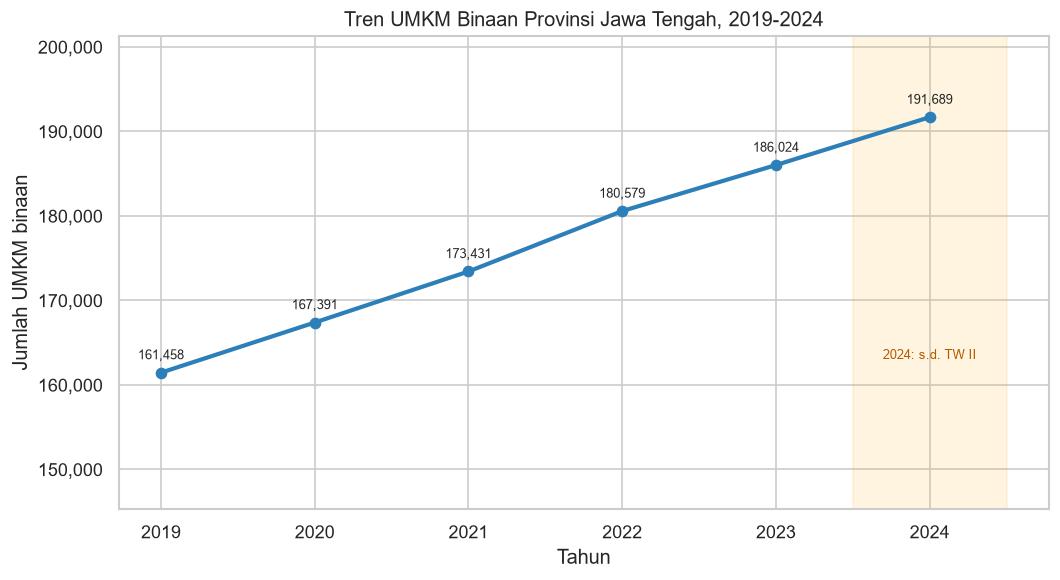

 tahun  umkm_binaan         catatan  pertumbuhan_yoy_persen
  2019       161458           penuh                     NaN
  2020       167391           penuh                3.674640
  2021       173431           penuh                3.608318
  2022       180579           penuh                4.121524
  2023       186024           penuh                3.015301
  2024       191689 s.d. TW II 2024                3.045306
CAGR 2019-2023: 3.60%


In [34]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(umkm.tahun, umkm.umkm_binaan, marker="o", lw=2.5, color="#2c7fb8")
for _, r in umkm.iterrows():
    ax.annotate(f"{r.umkm_binaan:,.0f}", (r.tahun, r.umkm_binaan),
                textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8)
ax.axvspan(2023.5, 2024.5, color="orange", alpha=0.12)
ax.text(2024, umkm.umkm_binaan.min() * 1.01, "2024: s.d. TW II",
        ha="center", fontsize=8, color="#b35c00")
ax.set_xlabel("Tahun")
ax.set_ylabel("Jumlah UMKM binaan")
ax.set_title("Tren UMKM Binaan Provinsi Jawa Tengah, 2019-2024")
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:,.0f}"))
ax.set_ylim(umkm.umkm_binaan.min() * 0.9, umkm.umkm_binaan.max() * 1.05)
plt.tight_layout()
plt.savefig("figures/fig7_umkm_series.png", bbox_inches="tight")
plt.show()

print(umkm.to_string(index=False))
print("CAGR 2019-2023: %.2f%%" % (((186024 / 161458) ** (1 / 4) - 1) * 100))

**Interpretasi bisnis:** populasi UMKM binaan tumbuh konsisten 3-4% per tahun (CAGR 2019-2023 = 3,6%). Angka 2024 baru mencakup TW II, jadi tidak sebanding dengan tahun penuh. Pertumbuhan yang stabil menandakan pasar sourcing yang terus bertambah, tetapi juga berarti Klay perlu **prioritas berbasis kualitas wilayah**, bukan hanya mengejar volume.

### 3.8 Komposisi sarana perdagangan

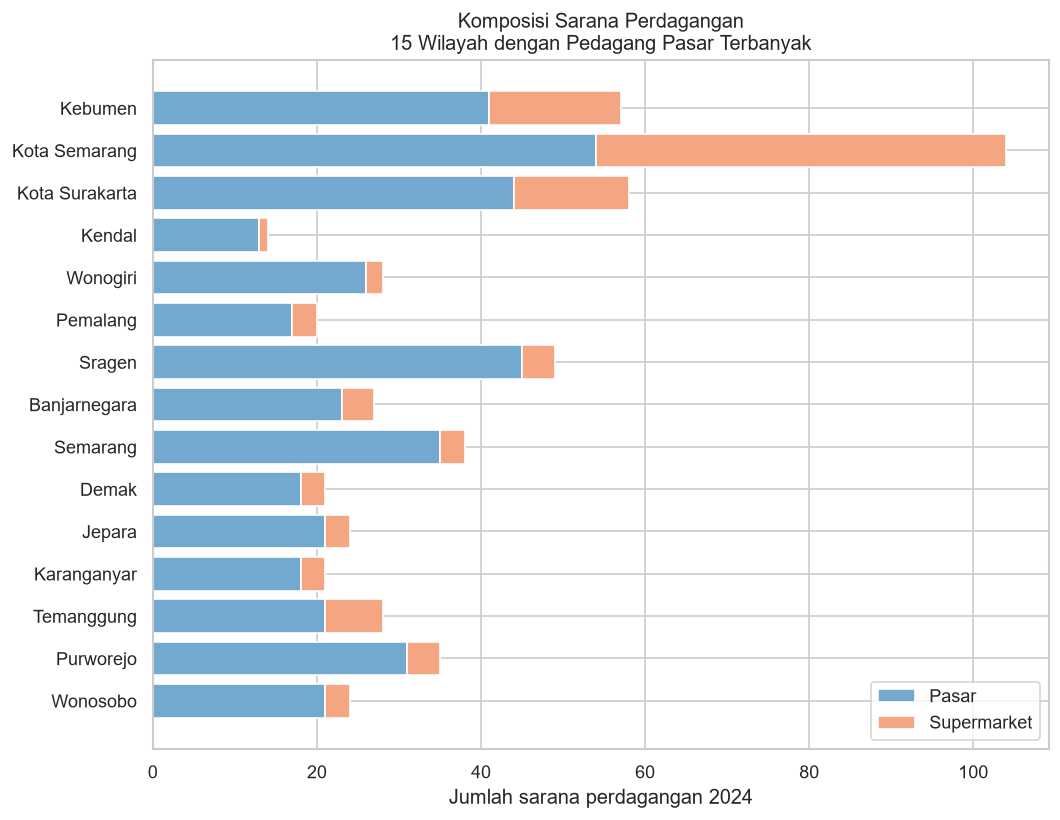

supermarket          163.0
pasar                804.0
pedagang_pasar    302196.0


In [35]:
top_retail = clean.nlargest(15, "pedagang_pasar").sort_values("pedagang_pasar")
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(top_retail.wilayah, top_retail.pasar, label="Pasar", color="#74a9cf")
ax.barh(top_retail.wilayah, top_retail.supermarket, left=top_retail.pasar,
        label="Supermarket", color="#f4a582")
ax.set_xlabel("Jumlah sarana perdagangan 2024")
ax.set_ylabel("")
ax.set_title("Komposisi Sarana Perdagangan\n15 Wilayah dengan Pedagang Pasar Terbanyak")
ax.legend(loc="lower right")
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:,.0f}"))
plt.tight_layout()
plt.savefig("figures/fig8_retail_mix.png", bbox_inches="tight")
plt.show()

print(clean[["supermarket", "pasar", "pedagang_pasar"]].sum().to_string())

**Interpretasi bisnis:** hampir seluruh ekosistem retail di wilayah terpilih berbasis pasar rakyat; supermarket hanya sebagian kecil. Ini memperkuat tesis bahwa **pasar tradisional dan pedagangnya adalah segmen utama Klay**, bukan hanya retail modern. Wilayah dengan pedagang pasar banyak tetapi supermarket sedikit (mis. Kebumen, Kendal) memiliki ketergantungan tinggi pada transaksi tunai - peluang untuk edukasi pembayaran digital dan pencatatan penjualan.

## Bagian 4 - Rancangan Bobot Ideal Customer Profile (ICP)

Bobot disusun dari lima komponen yang mencerminkan kesesuaian produk, kemampuan bayar, dan kemudahan akuisisi. Total bobot = 100%.

In [36]:
weights = pd.DataFrame({
    "Komponen": ["Ukuran Pasar", "Kepadatan Sektor Target", "Kesiapan Digital",
                 "Adopsi Pembayaran Digital", "Aktivitas Ekonomi"],
    "Indikator": [
        "Jumlah unit IMK; jumlah pedagang pasar",
        "IMK per 100.000 penduduk; pedagang pasar per 100.000 penduduk",
        "IPM; pengeluaran per kapita (proxy literasi digital dan daya beli)",
        "Simpanan per kapita; tabungan per kapita (proxy QRIS/non-tunai)",
        "PDRB per kapita",
    ],
    "Arah": ["+", "+", "+", "+", "+"],
    "Bobot": [0.25, 0.25, 0.20, 0.15, 0.15],
    "Justifikasi": [
        "Jumlah usaha mikro/kecil dan pedagang pasar menentukan volume merchant dan transaksi; Klay memonetisasi per outlet.",
        "F&B, retail, dan jasa adalah pengguna utama POS; kepadatan tinggi menurunkan biaya akuisisi per leads.",
        "IPM dan daya beli adalah proxy kesiapan digital karena persentase pengguna internet/ponsel per kab/kota tidak tersedia di sumber terpilih.",
        "Proxy kebiasaan nontunai dan akses layanan keuangan; QRIS ideal tetapi belum tersedia per kab/kota.",
        "Intensitas bisnis dan kemampuan bayar menentukan kesediaan berlangganan.",
    ],
})
weights

,Komponen,Indikator,Arah,Bobot,Justifikasi
0,Ukuran Pasar,Jumlah unit IMK; jumlah pedagang pasar,+,0.25,Jumlah usaha mikro/kecil dan pedagang pasar me...
1,Kepadatan Sektor Target,IMK per 100.000 penduduk; pedagang pasar per 1...,+,0.25,"F&B, retail, dan jasa adalah pengguna utama PO..."
2,Kesiapan Digital,IPM; pengeluaran per kapita (proxy literasi di...,+,0.20,IPM dan daya beli adalah proxy kesiapan digita...
3,Adopsi Pembayaran Digital,Simpanan per kapita; tabungan per kapita (prox...,+,0.15,Proxy kebiasaan nontunai dan akses layanan keu...
4,Aktivitas Ekonomi,PDRB per kapita,+,0.15,Intensitas bisnis dan kemampuan bayar menentuk...


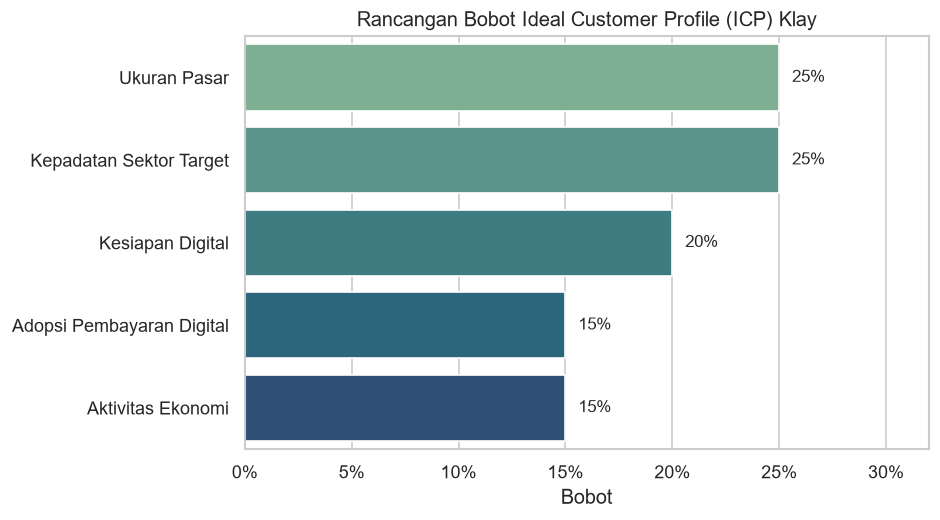

Total bobot: 100%


In [37]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(data=weights, y="Komponen", x="Bobot", hue="Komponen", legend=False,
            palette="crest", ax=ax)
for i, r in weights.iterrows():
    ax.text(r.Bobot + 0.006, i, f"{r.Bobot:.0%}", va="center", fontsize=10)
ax.set_xlim(0, 0.32)
ax.set_xlabel("Bobot")
ax.set_ylabel("")
ax.set_title("Rancangan Bobot Ideal Customer Profile (ICP) Klay")
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:.0%}"))
plt.tight_layout()
plt.savefig("figures/fig9_bobot_icp.png", bbox_inches="tight")
plt.show()

print("Total bobot:", f"{weights.Bobot.sum():.0%}")

### 4.1 Formula skor (rancangan, belum dihitung)

Untuk setiap wilayah $i$:

$$ICP_i = 0{,}25 \cdot U_i + 0{,}25 \cdot K_i + 0{,}20 \cdot D_i + 0{,}15 \cdot A_i + 0{,}15 \cdot E_i$$

dengan:

- $U_i$ = komponen Ukuran Pasar (rata-rata Min-Max jumlah unit IMK dan jumlah pedagang pasar),
- $K_i$ = komponen Kepadatan Sektor Target (rata-rata Min-Max IMK/100k dan pedagang/100k),
- $D_i$ = komponen Kesiapan Digital (rata-rata Min-Max IPM dan pengeluaran per kapita),
- $A_i$ = komponen Adopsi Pembayaran Digital (rata-rata Min-Max simpanan dan tabungan per kapita),
- $E_i$ = komponen Aktivitas Ekonomi (Min-Max PDRB per kapita).

Semua komponen berada pada 0-1, sehingga $ICP_i$ juga 0-1. **Skor akhir, peringkat, Top 5, dan uji sensitivitas bobot tidak dihitung di Tugas 2**; itu bagian dari milestone berikutnya.

### 4.2 Rasional pembobotan

- **Ukuran Pasar (25%)** dan **Kepadatan Sektor Target (25%)** mendapat bobot terbesar karena keduanya paling langsung menentukan jumlah leads dan potensi revenue.
- **Kesiapan Digital (20%)** lebih tinggi dari adopsi/aktivitas karena Klay adalah produk software: wilayah dengan literasi dan daya beli lebih baik lebih murah di-onboard dan lebih kecil churn-nya.
- **Adopsi Pembayaran Digital (15%)** penting, tetapi datanya hanya proxy (simpanan/tabungan), bukan QRIS merchant. Bobotnya dibatasi agar tidak mendominasi.
- **Aktivitas Ekonomi (15%)** memberi sinyal daya beli, tetapi PDRB per kapita tidak secara langsung mengukur kesiapan adopsi software.

## Bagian 5 - Kesimpulan dan Keterbatasan

### 5.1 Kesimpulan

1. Data 35 kabupaten/kota berhasil digabung dari empat sumber publik dengan kunci wilayah yang konsisten; tidak ada missing atau duplikat pada data mentah.
2. Setelah filter transparan, **30 wilayah** siap dianalisis. Lima wilayah gugur: Kabupaten Pekalongan (outlier kepadatan IMK) serta Kota Magelang, Kota Salatiga, Kota Pekalongan, dan Kota Tegal (basis IMK < 10.000 unit).
3. EDA menunjukkan dua klaster besar: **kabupaten berbasis manufaktur/retail tradisional** dengan volume besar tetapi IPM/PDRB menengah, dan **kota berbasis jasa/perdagangan** dengan IPM/PDRB tinggi tetapi basis IMK lebih kecil.
4. Rancangan bobot ICP memberi prioritas seimbang pada ukuran pasar dan kepadatan sektor (50% gabungan), dengan kesiapan digital sebagai faktor kualitas (20%), serta adopsi pembayaran dan aktivitas ekonomi sebagai pelengkap (30%).
5. Wilayah dengan kombinasi **kepadatan sektor tinggi + kesiapan digital menengah** (mis. Kebumen, Purbalingga, Temanggung, Batang) adalah kandidat menarik untuk ekspansi berbasis volume dan edukasi digital; kota besar (Semarang, Surakarta) lebih cocok untuk paket advanced.

### 5.2 Keterbatasan

- **Proxy sektor**: IMK hanya mencakup industri manufaktur mikro/kecil, bukan seluruh UMKM. Pedagang pasar hanya mencakup pedagang di pasar rakyat, bukan seluruh retail.
- **Komposisi sektor**: data publik yang dipakai tidak menyediakan proporsi ritel/F&B/jasa per kabupaten/kota, sehingga filter sektor tanpa transaksi harian rutin tidak diterapkan; IMK dan pedagang pasar hanya proxy. Ini adalah limitasi eksplisit, bukan data yang ditebak.
- **Data adopsi digital**: QRIS merchant per kabupaten/kota tidak tersedia publik; simpanan/tabungan per kapita hanya proxy tidak langsung.
- **Level agregasi**: UMKM binaan hanya tersedia di level provinsi dan hanya mencakup UMKM yang difasilitasi Dinkop, bukan total UMKM. Karena itu, data ini dipakai sebagai konteks, bukan fitur aditif.
- **Filter**: ambang 10.000 unit IMK mengeluarkan empat dari enam kota, sehingga hasil lebih representatif untuk kabupaten. Analisis kota kecil perlu dilakukan terpisah.
- **Desain cross-sectional**: data 2023-2024 tidak memungkinkan inferensi kausal atau tren jangka panjang per wilayah.
- **Normalisasi**: Min-Max sensitif terhadap outlier. Setelah filter, `simpanan_per_kapita_juta` masih sangat miring (didominasi Kota Semarang), sehingga pada milestone berikutnya perlu dipertimbangkan log-transform atau winsorization sebelum scoring.

### 5.3 Rencana milestone berikutnya

1. Finalisasi fitur dan uji sensitivitas bobot ICP.
2. Segmentasi wilayah dengan K-Means (jumlah klaster diuji dengan elbow/silhouette).
3. Perhitungan skor akhir dan penentuan Top 5 wilayah.
4. Validasi eksternal (mis. data QRIS atau survei lapangan) bila tersedia.

## Lampiran - Ekspor dataset

Dataset akhir dan daftar wilayah tereliminasi disimpan ke `data/processed/` agar dapat direproduksi dan dipakai pada milestone berikutnya. File CSV dipakai untuk pipeline, sedangkan file Excel diberi format agar mudah dibaca dan dipresentasikan.

In [38]:
helper_cols = ["gugur_imk_kecil", "gugur_outlier_density", "alasan_gugur"]
clean_export = clean.drop(columns=helper_cols)
clean_export.to_csv("data/processed/master_clean.csv", index=False)
eliminated.to_csv("data/processed/wilayah_tereliminasi.csv", index=False)

from openpyxl import load_workbook
from openpyxl.styles import Font, PatternFill, Alignment, Border, Side
from openpyxl.utils import get_column_letter

summary = pd.DataFrame({
    "Item": ["Judul", "Kelompok", "Anggota", "Wilayah awal", "Wilayah lolos",
             "Wilayah gugur", "Sumber data", "Periode"],
    "Keterangan": [
        "Market Prioritization UMKM - Klay",
        "13",
        "Ayu Safitri; Carissa Zia W. F; Gerard Harjuno N",
        "35 kabupaten/kota Jawa Tengah",
        f"{len(clean_export)} wilayah",
        f"{len(eliminated)} wilayah",
        "BPS Jateng, BPS Penduduk, BPS IPM, Dinkop Jateng",
        "2023-2024",
    ],
})

xlsx_path = "data/processed/Tugas2_DS_Kelompok13_Data.xlsx"
elim_cols = ["wilayah", "tipe", "imk_unit", "imk_per_100k", "alasan_gugur"]
with pd.ExcelWriter(xlsx_path, engine="openpyxl") as writer:
    summary.to_excel(writer, sheet_name="Ringkasan", index=False)
    master.to_excel(writer, sheet_name="Data Mentah", index=False)
    clean_export.to_excel(writer, sheet_name="Data Bersih", index=False)
    eliminated[elim_cols].to_excel(writer, sheet_name="Wilayah Gugur", index=False)
    umkm.to_excel(writer, sheet_name="UMKM Provinsi", index=False)
    weights.to_excel(writer, sheet_name="Bobot ICP", index=False)

wb = load_workbook(xlsx_path)
header_fill = PatternFill("solid", fgColor="1F4E79")
header_font = Font(bold=True, color="FFFFFF", size=10)
alt_fill = PatternFill("solid", fgColor="EAF2F8")
thin = Side(style="thin", color="B7C9D6")
border = Border(left=thin, right=thin, top=thin, bottom=thin)

for ws in wb.worksheets:
    ws.freeze_panes = "B2"
    ws.auto_filter.ref = ws.dimensions
    ws.sheet_view.showGridLines = False
    ws.row_dimensions[1].height = 34
    for cell in ws[1]:
        cell.fill = header_fill
        cell.font = header_font
        cell.alignment = Alignment(horizontal="center", vertical="center", wrap_text=True)
        cell.border = border
    for r in range(2, ws.max_row + 1):
        for cell in ws[r]:
            cell.border = border
            cell.alignment = Alignment(vertical="top", wrap_text=True)
            if r % 2 == 0:
                cell.fill = alt_fill
        ws.row_dimensions[r].height = 28
    for col in ws.columns:
        letter = get_column_letter(col[0].column)
        max_len = max(len(str(c.value)) if c.value is not None else 0 for c in col)
        ws.column_dimensions[letter].width = min(max(12, max_len + 2), 34)

    for cell in ws[1]:
        header = str(cell.value)
        if header == "Bobot":
            fmt = "0%"
        elif any(k in header for k in ["norm", "komp_", "ipm", "per_100k", "per_kapita", "growth", "pertumbuhan"]):
            fmt = "0.000"
        elif any(k in header for k in ["unit", "tenaga_kerja", "pasar", "supermarket", "penduduk_ribu", "pdrb", "simpanan", "tabungan", "pengeluaran", "binaan"]):
            fmt = "#,##0"
        else:
            fmt = None
        if fmt:
            for row in ws.iter_rows(min_row=2, min_col=cell.column, max_col=cell.column):
                for c in row:
                    c.number_format = fmt

for ws_name, widths in {
    "Ringkasan": {"A": 22, "B": 78},
    "Wilayah Gugur": {"A": 22, "B": 12, "C": 14, "D": 14, "E": 52},
    "UMKM Provinsi": {"A": 10, "B": 16, "C": 24, "D": 24},
    "Bobot ICP": {"A": 28, "B": 52, "C": 8, "D": 10, "E": 72},
}.items():
    ws = wb[ws_name]
    for col, width in widths.items():
        ws.column_dimensions[col].width = width
    for r in range(2, ws.max_row + 1):
        if ws_name == "Bobot ICP":
            ws.row_dimensions[r].height = 56
        elif ws_name == "Ringkasan":
            ws.row_dimensions[r].height = 30
        else:
            ws.row_dimensions[r].height = 34

wb.save(xlsx_path)

print("master_clean.csv        :", clean_export.shape)
print("wilayah_tereliminasi.csv:", eliminated.shape)
print("Excel styled            :", xlsx_path)
print("\nKolom master_clean:")
print(", ".join(clean_export.columns))

master_clean.csv        : (30, 41)
wilayah_tereliminasi.csv: (5, 30)
Excel styled            : data/processed/Tugas2_DS_Kelompok13_Data.xlsx

Kolom master_clean:
kode_wilayah, wilayah, penduduk_ribu, kepadatan_per_km2, tipe, ipm, pengeluaran_per_kapita, harapan_lama_sekolah, rata_rata_lama_sekolah, usia_harapan_hidup, imk_unit, imk_tenaga_kerja, imk_nilai_produksi, pdrb_per_kapita_2024, supermarket, pasar, pedagang_pasar, simpanan_2024, tabungan_2024, prov_umkm_growth_2023, prov_umkm_binaan_2023, imk_per_100k, pedagang_per_100k, pasar_per_100k, simpanan_per_kapita_juta, tabungan_per_kapita_juta, sektor_target_per_100k, ukuran_pasar_imk, ukuran_pasar_pedagang, kepadatan_imk, kepadatan_pedagang, kesiapan_ipm, kesiapan_pengeluaran, adopsi_simpanan, adopsi_tabungan, aktivitas_pdrb, komp_ukuran_pasar, komp_kepadatan_sektor, komp_kesiapan_digital, komp_adopsi_digital, komp_aktivitas_ekonomi
